# When the engine beats a regression: the exact risk of CrusherBayes given its scalars, the virtual plant that tests it and the information ceiling of the capacity base

**Question:** Under what conditions does CrusherBayes, the calibration of the engine with a structural discrepancy, predict a survey better than an empirical regression on the same regressors, how much of that is decided by the engine's own curvature, the discrepancy scale and the design of the surveys, and what can ten surveys never tell about the engine's scalars?

- **Level:** 4, the product's proposed method
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 75 minutes

## Objectives

By the end of this notebook you can:

- write the predictive mean and variance of CrusherBayes for fixed scalars, show that the mean is a ridge regression toward the engine's best plane plus the engine's departure from that plane, and check both forms against the product's own predictive function;
- measure the engine's departure from a plane on a set of surveys, and say why it is zero for the throughput and a few kilowatts for the power;
- compute the exact risk of the predictor on a virtual plant, find the share of curvature at which the engine stops helping, and confirm the formula with a Monte Carlo;
- read the capacity study: when an engine of the right form pays, when one of the wrong form costs, and why an affine engine is only a shrinkage target;
- find the fixed-design risk-optimal discrepancy scale, see why the product's value sits next to it, and read the held-out optimum of the committed study;
- compute the information ceiling of the capacity base from the ten surveys and say what no number of surveys at this speed can change;
- name where the closed form stops describing the method, and apply the diagnostics to a table of your own.

## Setup

Numpy and matplotlib; the CrusherBayes module and the harness of the manuscript's study (`manuscripts/crusherbayes-theory/sim`) are imported by path. The notebook does not run the sampler.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader, the CrusherBayes module (its predictive function, its priors and the engine), and the harness modules for the virtual plants, the pools of operating points and the closed-form risk.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline and the study's harness are imported
# by path
ROOT = Path("../../..").resolve()
STUDY = ROOT / "manuscripts/crusherbayes-theory"
sys.path.insert(0, str(ROOT / "data-pipeline"))
sys.path.insert(0, str(STUDY / "sim"))
# Public functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import crusherbayes as cb
from pipeline.hp500 import loo
from pipeline.model.crusher import capacity, evaluate
from pipeline.model.crusher.envelope import check_envelope
from pipeline.model.crusher.hp500 import operating_from_survey
import engines
import inputs
import plants
import pools
import predictors
import theory
from heldout_uq import ROCHA, WI_BLEND, rocha_shape
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`; `data/derived/hp500/crusherbayes.json`, through the harness reader, for the scalars fitted to all ten surveys, the fitted discrepancy and the noise scales; and from the study of the CrusherBayes theory manuscript, under `manuscripts/crusherbayes-theory/data/`, the summaries `pilot.json`, `identifiability.json`, `tau_coverage.json` and the exact-route cells `exact/Ccap_*.json` and `exact/V1_*.json`. Those cells come from simulations of 1,900 replicates with 200 test points each, baked offline; a notebook never reruns them, and a number read from them is called committed in the text. Every other number is computed here, on at most 300 operating points.

The cell reads the surveys, the fit to all ten and the summaries by key; a missing file stops it with its path, and nothing stands in for it.

In [2]:
# The ten surveys, the fit to all ten that the product ships (the scalars, the discrepancy and the noise
# scales) and the study's summaries, read by key
surveys = read_surveys().accepted
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
y = {"tph": np.array([s.feed_tph for s in surveys]), "kW": np.array([s.power_kw for s in surveys])}
fit = inputs.load_fit()


def read_summary(relative):
    # A missing summary stops the run with its path; there is no fallback number
    path = STUDY / "data" / relative
    if not path.is_file():
        raise FileNotFoundError("missing summary: " + path.relative_to(ROOT).as_posix())
    return json.loads(path.read_text(encoding="utf-8"))


NS = (10, 20, 40, 80, 160)
SIZES = [("real", 10)] + [(d, n) for d in ("surveys", "wide", "extrapolation") for n in NS]
ccap = {(k, d, n): read_summary(f"exact/Ccap_{k}-{d}-n{n}.json") for k in engines.ANALYTIC for d, n in SIZES}
v1_cells = {(a, d): read_summary(f"exact/V1_{a}_k0-{d}-n160.json") for a in ("a1", "a2") for d in ("surveys",)}
v1_cells[("a1_k2", "surveys")] = read_summary("exact/V1_a1_k2-surveys-n160.json")
v1_cells[("a1_k2", "extrapolation")] = read_summary("exact/V1_a1_k2-extrapolation-n160.json")
v1_cells[("a1", "extrapolation")] = read_summary("exact/V1_a1_k0-extrapolation-n160.json")
pilot = read_summary("pilot.json")
ident = read_summary("identifiability.json")
tau_cov = read_summary("tau_coverage.json")
reps = ccap[("rocha", "surveys", 160)]["reps"]
text = ('surveys: {} | capacity cells read: {} | replicates per cell: {} | '
        'study sigma {:.3f} kW and {:.1f} t/h')
print(text.format(len(surveys), len(ccap), reps, ident["sigma"]["kW"], ident["sigma"]["tph"]))

surveys: 10 | capacity cells read: 48 | replicates per cell: 1900 | study sigma 38.812 kW and 145.2 t/h


## Method

### The predictive of CrusherBayes given its scalars

**Hypothesis and verdicts.** The theory study states, before running it, three claims about the proposed method. With the scalars given, CrusherBayes beats least squares on the same regressors if and only if the curvature term of (7) below is positive. On the throughput, where the engine's capacity is affine, the gain is zero up to a shrinkage effect, and with a capacity law curved like the plant's it grows with the width of the window and is largest under extrapolation. Surveys at a fixed speed cannot narrow the capacity base beyond a ceiling, and surveys at varied speed would narrow it by more than doubling their number. The verdicts, as the manuscript records them and as the cells below measure them: the first claim held; the second held for the engine of the plant's own form and failed for the engine with half its exponents, which lost on the wide window and under extrapolation; the ceiling held and the clause about the speed failed.

CrusherBayes writes each output $t$ of a survey, the throughput or the power, as the engine at eight scalars $\boldsymbol\theta$ plus a discrepancy plane plus noise, $y = f_t(\boldsymbol\theta;\mathbf x) + \tilde{\mathbf z}^{\top}\mathbf d + \varepsilon$, with the regressors $\tilde{\mathbf z} = (1, z_c, z_f)$ (the standardized setting and feed size), a prior $\mathbf d \sim N(\mathbf 0, \tau_t^2\mathbf I)$ and noise of standard deviation $\sigma_t$ (Kennedy and O'Hagan, 2001). The full method samples $\boldsymbol\theta$ and $\sigma_t$. **This notebook fixes them**, because with the scalars given the predictive is exact in closed form, and the closed form is what the theory analyses. Let $\mathbf Z$ hold the regressors of the $n$ training surveys, $\mathbf G = \mathbf Z^{\top}\mathbf Z$, $\lambda_t = \sigma_t^2/\tau_t^2$, and $\mathbf f_t$ the engine on the training surveys. The predictive of a held-out survey with regressors $\tilde{\mathbf z}_h$ is normal, with

$$\hat y_t(\mathbf x_h) = f_t(\boldsymbol\theta;\mathbf x_h) + \tilde{\mathbf z}_h^{\top}(\mathbf G + \lambda_t\mathbf I)^{-1}\mathbf Z^{\top}(\mathbf y_t - \mathbf f_t) \tag{1}$$

$$s_t^2(\mathbf x_h) = \sigma_t^2\bigl(1 + \tilde{\mathbf z}_h^{\top}(\mathbf G + \lambda_t\mathbf I)^{-1}\tilde{\mathbf z}_h\bigr) \tag{2}$$

that is, the engine corrected by a ridge fit of its own residuals. The cell holds out survey 5, fixes the scalars at their shipped values with the noise at the prior medians, computes (1) and (2) with numpy, and sets the result beside the product's `_Problem.predict`, which conditions the discrepancy exactly as the sampler does at one posterior sample, and beside the harness's closed-form predictor.

In [3]:
# Hold out survey 5 and fit the other nine with the engine's scalars fixed at their shipped values
held = 4
train = np.array([i for i in range(10) if i != held])
theta = cb.nominal_theta()
problem = cb._Problem(css, f80, y, train)
via_product = problem.predict(theta, held)
# The engine at those scalars on every survey, and the discrepancy regressors in the training standardization
shipped = [evaluate(op, cb.scalars_of(theta)) for op in problem.ops]
engine_pair = (np.array([r.throughput_tph for r in shipped]), np.array([r.power_kw for r in shipped]))
f_all = dict(zip(cb.TARGETS, engine_pair))
Z = cb.design(css[train], f80[train], problem.mu, problem.sd)
z_h = cb.design(css[[held]], f80[[held]], problem.mu, problem.sd)[0]
closed = {}
print("target  lambda  closed mean  product mean  closed var  product var  harness mean  largest gap")
row_format = "{:6s} {:7.3f} {:12.4f} {:13.4f} {:11.3f} {:12.3f} {:12.4f} {:11.1e}"
for k, t in enumerate(cb.TARGETS):
    sigma, tau = math.exp(theta[cb.N_ENGINE + k]), cb.DISCREPANCY_SD[t]
    lam = sigma**2 / tau**2
    # Equations (1) and (2): the engine plus the ridge fit of its residuals, and the variance of the predictive
    A = np.linalg.inv(Z.T @ Z + lam * np.eye(3))
    mean = f_all[t][held] + z_h @ A @ Z.T @ (y[t][train] - f_all[t][train])
    var = sigma**2 * (1 + z_h @ A @ z_h)
    harness = predictors.cb_fixed(Z, y[t][train], f_all[t][train], z_h[None, :], f_all[t][[held]], sigma, tau)
    gap = max(abs(mean - via_product[t][0]), abs(var - via_product[t][1]), abs(mean - harness[0][0]))
    closed[t] = mean
    print(row_format.format(t, lam, mean, via_product[t][0], var, via_product[t][1], harness[0][0], gap))
    factor = loo.band_factor(0.8)
    low, high = mean - factor * math.sqrt(var), mean + factor * math.sqrt(var)
    print(f"{'':6s} 80% interval, factor {factor} {low:.1f} to {high:.1f}, measured {y[t][held]:.1f}")

target  lambda  closed mean  product mean  closed var  product var  harness mean  largest gap
tph      0.184    1118.1651     1118.1651    4504.619     4504.619    1118.1651     4.8e-11
       80% interval, factor 1.2816 1032.1 to 1204.2, measured 1124.0
kW       0.174     289.8989      289.8989     281.609      281.609     289.8989     2.5e-12
       80% interval, factor 1.2816 268.4 to 311.4, measured 325.0


The three computations agree: the largest gap between the closed form, the product's function and the harness is 4.8e-11 on the throughput and 2.5e-12 on the power, which is rounding. Equations (1) and (2) are therefore what the product evaluates at every posterior sample, with the predictive variance 4504.619 (t/h)$^2$ for the throughput and 281.609 kW$^2$ for the power at these noise scales. The shrinkage $\lambda$ is 0.184 and 0.174, small against the eigenvalues of $\mathbf G$, which for nine surveys are of the order of nine. The 80 percent interval, with the factor 1.2816 of `loo.band_factor`, is 1032.1 to 1204.2 t/h for the throughput and covers the measured 1124.0; for the power it is 268.4 to 311.4 kW and misses the measured 325.0, because the noise is fixed at its prior median of 15 kW while the plant's own residual is near 39 kW (the fitted noise scale is 38.812 kW): the sampler learns it. The sampler's predictive is a mixture of such normals over the posterior of the scalars; the rest of the notebook studies one component of the mixture, because the risk of one component is exact.

### The ridge form: least squares plus the engine's departure from its plane

Project the engine on the regressors of the training surveys: $\mathbf b = \mathbf G^{-1}\mathbf Z^{\top}\mathbf f$ is the engine's best plane, and $\mathbf e = \mathbf f - \mathbf Z\mathbf b$ is what no plane in the setting and the feed size represents. At the held-out survey write $e_h = f(\mathbf x_h) - \tilde{\mathbf z}_h^{\top}\mathbf b$. Algebra on (1) gives the ridge identity of the manuscript,

$$\hat y_t(\mathbf x_h) = \tilde{\mathbf z}_h^{\top}(\mathbf G + \lambda\mathbf I)^{-1}\bigl(\mathbf Z^{\top}\mathbf y + \lambda\,\mathbf b\bigr) + e_h \tag{3}$$

a ridge regression of the survey on the regressors that shrinks toward the engine's plane $\mathbf b$ instead of toward zero, plus the engine's departure from that plane at the held-out survey. Two consequences carry the rest of the notebook. At $\lambda = 0$ the predictor is least squares on the regressors plus $e_h$: the engine contributes only its departure from a plane. At $\lambda > 0$ the engine also contributes its plane, as a shrinkage target. The cell computes both forms for both outputs.

In [4]:
# The engine's best plane b over the nine training surveys, its departure e_h at the held-out survey, and the
# two forms of the mean
print("target  e_h  engine plane at h  closed mean  ridge form  lambda = 0: LS + e_h  lambda ~ 0 predictor")
for k, t in enumerate(cb.TARGETS):
    sigma, tau = math.exp(theta[cb.N_ENGINE + k]), cb.DISCREPANCY_SD[t]
    b = np.linalg.lstsq(Z, f_all[t][train], rcond=None)[0]
    e_h = f_all[t][held] - z_h @ b
    # Ridge toward the engine's plane, plus the engine's departure from it at the held-out survey
    lam = sigma**2 / tau**2
    ridge = theory.ridge_identity_mean(Z, y[t][train], f_all[t][train], z_h[None, :], f_all[t][[held]], lam)[0]
    # No shrinkage: least squares on the regressors plus e_h, and the predictor with a prior scale of a million
    plane_ls = z_h @ np.linalg.lstsq(Z, y[t][train], rcond=None)[0]
    args = (Z, y[t][train], f_all[t][train], z_h[None, :], f_all[t][[held]])
    wide_prior = predictors.cb_fixed(*args, sigma, 1e6)[0][0]
    row = (e_h, z_h @ b, closed[t], ridge, plane_ls + e_h, wide_prior)
    print(f"{t:6s} {row[0]:8.3f} {row[1]:14.3f} {row[2]:12.4f} {row[3]:11.4f} {row[4]:22.4f} {row[5]:20.4f}")

target  e_h  engine plane at h  closed mean  ridge form  lambda = 0: LS + e_h  lambda ~ 0 predictor
tph       0.000       1106.711    1118.1651   1118.1651              1117.0038            1117.0038
kW        5.653        409.533     289.8989    289.8989               288.1213             288.1213


The ridge form (3) returns 1118.1651 for the throughput and 289.8989 for the power, the closed-form values of (1) to four decimals. With the prior scale raised to a million, so that $\lambda$ is practically zero, the predictor gives 1117.0038 and 288.1213, and these are least squares on the nine surveys plus $e_h$: the last two columns coincide. The departure $e_h$ is 0.000 t/h for the throughput and 5.653 kW for the power. On this survey the engine's curvature moves the power prediction by 5.653 kW and the throughput prediction by nothing, and the shrinkage toward the engine's plane is what lifts the throughput from 1117.0038 to 1118.1651 and the power from 288.1213 to 289.8989.

### The capacity function is affine in the setting

The throughput of the engine on the HP500 lane is the product's capacity function, $Q = Q_{\mathrm{ref}}\,\frac{c + t/2}{38}\,s\,e^{1-s}$, with $t$ the throw in millimetres and $s$ the speed over its optimum, so at the lane's fixed throw of 34 mm and its speed this is the straight line $Q_{\mathrm{ref}}(c + 17)/38$ in the setting $c$, and does not depend on the feed size at all. The cell calls `capacity.throughput` over the settings of the calibrated envelope at the fitted capacity base, fits a line through the result and reports how far the function is from it.

In [5]:
# The engine's own capacity function at the fitted capacity base, over the settings of the calibrated envelope
# at the lane's throw and speed
q_fit = cb.scalars_of(np.concatenate([fit.theta0, [0.0, 0.0]])).q_ref_tph
op0 = problem.ops[0]
settings = np.linspace(38.0, 55.0, 18)
capacity_t_h = np.array([
    capacity.throughput(op0.machine, c, op0.throw_mm, op0.speed_rpm, True, hp500_q_ref=q_fit) for c in settings
])
# A straight line through it, and the same line written as Q_ref (c + 17) / 38
slope, intercept = np.polyfit(settings, capacity_t_h, 1)
miss = np.abs(capacity_t_h - (slope * settings + intercept)).max() / capacity_t_h.mean()
text = "throw {} mm, speed {} rpm, fitted Q_ref {:.2f} t/h"
print(text.format(op0.throw_mm, op0.speed_rpm, q_fit))
text = "slope over Q_ref/38: {:.4f} | intercept over 17 Q_ref/38: {:.4f}"
print(text.format(slope * 38 / q_fit, intercept * 38 / (17 * q_fit)))
print("largest gap to the line, relative: below 1e-9 is {}".format(miss < 1e-9))

throw 34 mm, speed 360 rpm, fitted Q_ref 646.35 t/h
slope over Q_ref/38: 1.0000 | intercept over 17 Q_ref/38: 1.0000
largest gap to the line, relative: below 1e-9 is True


The capacity base fitted to the ten surveys is 646.35 t/h. The line through the function has a slope of 1.0000 times $Q_{\mathrm{ref}}/38$ and an intercept of 1.0000 times $17\,Q_{\mathrm{ref}}/38$, and the largest gap between the function and the line is below 1e-9 of its level: the capacity is exactly $Q_{\mathrm{ref}}(c + 17)/38$ at throw 34 mm and speed 360 rpm. A function of the setting alone lies in the span of $(1, c, f_{80})$ whatever the value of $Q_{\mathrm{ref}}$, which is the reason the next cell finds no departure for the throughput. It does not say that the throughput of the plant is affine, only that the engine's is.

### The engine's departure from a plane on the ten surveys

On the HP500 lane at its fixed speed the engine's throughput is $Q_{\mathrm{ref}}(c + 17)/38$, with $c$ the setting in millimetres: an affine function of the setting whatever the eight scalars, so its departure from any plane in $(1, c, f_{80})$ is zero. The power is not affine, because it multiplies the capacity by a specific energy that depends on the feed and product sizes. With all ten surveys as the training set, the engine's departure and the measured residual of a least-squares plane are

$$\mathbf e = \mathbf f - \mathbf Z(\mathbf Z^{\top}\mathbf Z)^{-1}\mathbf Z^{\top}\mathbf f, \qquad \hat{\mathbf r} = \mathbf y - \mathbf Z(\mathbf Z^{\top}\mathbf Z)^{-1}\mathbf Z^{\top}\mathbf y \tag{4}$$

The measured residual $\hat{\mathbf r}$ holds the plant's own curvature $\mathbf r$ plus the part of the noise that the plane cannot absorb, so its root mean square overstates the curvature. The cell computes both at the fitted scalars (the posterior means in the product's document) and at the shipped ones, for both outputs, with the correlation of $\mathbf e$ and $\hat{\mathbf r}$, which the study's pilot also reports for the calibrated backbone.

In [6]:
# The engine at the fitted scalars (the posterior means the product ships) and at the shipped ones, on the ten
# surveys
Z10 = cb.design(css, f80, np.array([css.mean(), f80.mean()]), np.array([css.std(), f80.std()]))
fitted_scalars = cb.scalars_of(np.concatenate([fit.theta0, [0.0, 0.0]]))
fitted = [evaluate(op, fitted_scalars) for op in problem.ops]
fitted_pair = (np.array([r.throughput_tph for r in fitted]), np.array([r.power_kw for r in fitted]))
engine_at = {"fitted": fitted_pair, "shipped": engine_pair}
plane = {}
print("scalars  target  rms of e  largest |e| over level  rms of r-hat  correlation of e and r-hat")
for label, pair in engine_at.items():
    for t, f in zip(cb.TARGETS, pair):
        # Equation (4): the part of the engine and of the measurement that no plane in (1, CSS, f80) represents
        e = f - Z10 @ np.linalg.lstsq(Z10, f, rcond=None)[0]
        r_hat = y[t] - Z10 @ np.linalg.lstsq(Z10, y[t], rcond=None)[0]
        plane[(label, t)] = (e, r_hat)
        relative = np.abs(e).max() / np.abs(f).mean()
        rho = f"{np.corrcoef(e, r_hat)[0, 1]:.3f}" if relative > 1e-9 else "undefined"
        flag = "below 1e-9" if relative < 1e-9 else f"{relative:.3f}"
        e_rms, r_rms = np.sqrt(np.mean(e**2)), np.sqrt(np.mean(r_hat**2))
        print(f"{label:8s} {t:6s} {e_rms:9.3f} {flag:>22s} {r_rms:12.3f} {rho:>24s}")
text = "pilot of the study (engine of the calibrated backbone): power departure sd {} kW, correlation {}"
print(text.format(pilot["kW"]["engine_departure_sd"], pilot["kW"]["corr"]))

scalars  target  rms of e  largest |e| over level  rms of r-hat  correlation of e and r-hat
fitted   tph        0.000             below 1e-9      119.646                undefined
fitted   kW         6.132                  0.047       33.182                    0.463
shipped  tph        0.000             below 1e-9      119.646                undefined
shipped  kW         5.633                  0.033       33.182                    0.450
pilot of the study (engine of the calibrated backbone): power departure sd 5.638 kW, correlation 0.452


The figure draws the two departures survey by survey, the measured residual as grey bars and the engine's departure as black bars, for the throughput on the left and the power on the right, at the fitted scalars.

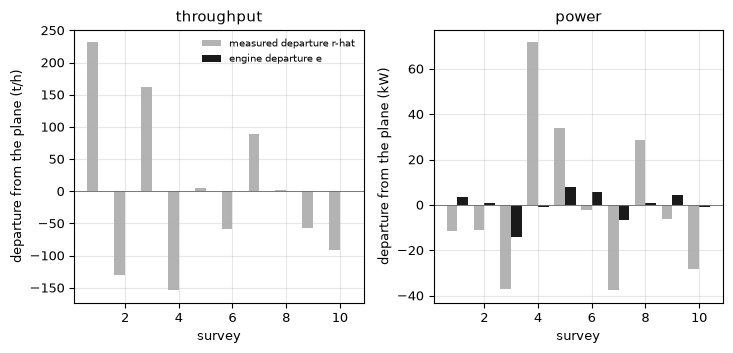

In [7]:
# Figure 1: the plant's departure from its plane (bars) against the engine's (dots), survey by survey,
# throughput left and power right
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.6))
x = np.arange(1, 11)
for ax, t, unit in zip(axes, cb.TARGETS, ("t/h", "kW")):
    e, r_hat = plane[("fitted", t)]
    ax.bar(x - 0.2, r_hat, width=0.4, color="0.7", label="measured departure r-hat")
    ax.bar(x + 0.2, e, width=0.4, color="0.1", label="engine departure e")
    ax.axhline(0, color="0.4", lw=0.6)
    ax.set_xlabel("survey")
    ax.set_ylabel(f"departure from the plane ({unit})")
    ax.set_title("throughput" if t == "tph" else "power")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

For the throughput the engine's departure is below 1e-9 of its level at both sets of scalars, so the black bars of the left panel do not exist, while the measured residual has a root mean square of 119.646 t/h: the engine has no curvature to offer the throughput prediction, only a plane. For the power the engine departs from a plane by 6.132 kW root mean square at the fitted scalars and 5.633 kW at the shipped ones, against a measured residual of 33.182 kW, and the two are positively correlated (0.463 and 0.450; the study's pilot, with the engine of the calibrated backbone, gives 0.452). The figure does not show whether that correlation is more than chance: it rests on ten points, and the last section puts an interval on it. It also hides that the grey bars include noise that no engine could explain.

## Comparison

### The exact risk of the predictor on a virtual plant

Whether the engine's curvature helps depends on the plant's mean function, which no finite set of surveys reveals. The study therefore builds virtual plants whose mean function is known, simulates surveys from them and compares the predictor with least squares. With the scalars fixed the risk is exact. For a training design with regressors $\mathbf Z$, noise $\sigma$, the plant's mean $\boldsymbol\mu$ projected as in (4) into $\boldsymbol\beta$ and $\mathbf r$, the engine into $\mathbf b$ and $\mathbf e$, $\boldsymbol\delta = \mathbf b - \boldsymbol\beta$ and $\mathbf A_\lambda = (\mathbf G + \lambda\mathbf I)^{-1}$, the expected squared error at a held-out point, over training and test noise, is

$$R_\lambda(\mathbf x_h) = \bigl(r_h - e_h - \lambda\,\tilde{\mathbf z}_h^{\top}\mathbf A_\lambda\boldsymbol\delta\bigr)^2 + \sigma^2\,\tilde{\mathbf z}_h^{\top}\mathbf A_\lambda\mathbf G\mathbf A_\lambda\tilde{\mathbf z}_h + \sigma^2 \tag{5}$$

$$R_{\mathrm{LS}}(\mathbf x_h) = r_h^2 + \sigma^2\,\tilde{\mathbf z}_h^{\top}\mathbf G^{-1}\tilde{\mathbf z}_h + \sigma^2 \tag{6}$$

Nothing assumes that the plant is the engine, that the prior is right or that the model's noise equals the plant's. At $\lambda = 0$ the difference of the two reduces to $e_h(2 r_h - e_h)$, so over held-out points, with $\rho$ the correlation of $e$ with $r$ and $\kappa = \lVert e\rVert/\lVert r\rVert$,

$$\mathbb E\,[R_{\mathrm{LS}} - R_0] = 2\langle e, r\rangle - \lVert e\rVert^2 = \lVert r\rVert^2\,(2\rho\kappa - \kappa^2) \tag{7}$$

which is positive if and only if $0 < \kappa < 2\rho$. The engine helps only through curvature that points the way the plant's does and is no more than twice as large; one of the wrong sign always loses. The noise does not enter (7): the gain is a bias term, and it does not decay with the number of surveys.

The plants are the family $\boldsymbol\mu_\alpha = \mathbf z_{\mathrm{ref}}^{\top}(\mathbf b_0 + \mathbf d_0) + \alpha\,e_0$: the plant fitted to the ten surveys with a share $\alpha$ of the engine's own power curvature $e_0$. Then $\alpha = 1$ is the fitted plant, $\alpha = 0$ is a plant that is a plane, $\alpha = -1$ reverses the engine's curvature, and (7) says the gain is $(2\alpha - 1)\lVert e_0\rVert^2$, changing sign at $\alpha = 1/2$. The cell builds the pool of 300 points, evaluates the engine on it at the fitted scalars and fits the family.

In [8]:
# A small pool of 300 operating points uniform in the surveys window (CSS 38 to 55 mm, f80 47 to 140 mm, 360
# rpm) and the engine at the fitted scalars on it
pool = pools.window_points("surveys", 300)
engine_pool = engines.product_eval(pool, fit.theta0, workers=1, jac=False)
f_pool = engine_pool["kW"]
mu_ref, sd_ref = inputs.reference_standardization()
z_ref = pools.design_matrix(pool, mu_ref, sd_ref)
# The plant family V1(alpha): the fitted plant with a share alpha of the engine's own power curvature e_0
# (alpha = 1 is the fitted plant)
basis = plants.V1Basis.fit(f_pool, z_ref)
sigma_kw, tau_kw = fit.sigma["kW"], cb.DISCREPANCY_SD["kW"]
lam_prod = sigma_kw**2 / tau_kw**2
text = "points {} | engine failures {} | rms of e_0 {:.3f} kW | sigma {:.3f} kW | sigma^2 {:.1f} kW^2 | lambda {:.4f}"
print(text.format(pool.shape[0], int((~engine_pool["ok"]).sum()), basis.rms_e0, sigma_kw, sigma_kw**2, lam_prod))

points 300 | engine failures 0 | rms of e_0 4.148 kW | sigma 38.812 kW | sigma^2 1506.4 kW^2 | lambda 1.1623


The pool holds 300 operating points uniform in the window of the surveys. The next cell draws one training design of 100 points and 150 test points from it and evaluates, for five values of $\alpha$, the exact risk difference of (5) and (6) at $\lambda = 0$ and at the product's $\lambda$, next to the alignment quantities $\rho$ and $\kappa$ and the corollary's expression (7).

In [9]:
# One training design of 100 points and 150 test points from the pool; the exact risk of equations (5) and (6)
# for each alpha
rng = np.random.default_rng(20261119)
train_i, test_i, _ = pools.draw_design(rng, "surveys", 100, 150, pool, np.arange(300))
m_tr, s_tr = pools.standardization(pool[train_i])
Z_tr = pools.design_matrix(pool[train_i], m_tr, s_tr)
Z_te = pools.design_matrix(pool[test_i], m_tr, s_tr)
plant_mean = {}
risk_table = {}
print("training points {} | test points {}".format(train_i.size, test_i.size))
print("alpha  rho  kappa  2<e,r>-|e|^2  gain, lambda 0  gain, product lambda")
for alpha in (-1.0, 0.0, 0.5, 1.0, 2.0):
    mu = basis.mean(alpha, 0.0, f_pool, z_ref, fit.d0["kW"])
    plant_mean[alpha] = mu
    beta = np.linalg.lstsq(Z_tr, mu[train_i], rcond=None)[0]
    b = np.linalg.lstsq(Z_tr, f_pool[train_i], rcond=None)[0]
    r_h, e_h = mu[test_i] - Z_te @ beta, f_pool[test_i] - Z_te @ b
    args = (Z_tr, mu[train_i], f_pool[train_i], Z_te, mu[test_i], f_pool[test_i], sigma_kw)
    risk_ls = theory.expected_sq_error_ls(Z_tr, mu[train_i], Z_te, mu[test_i], sigma_kw)
    gain_zero = (risk_ls - theory.expected_sq_error(*args, 0.0)).mean()
    gain_prod = (risk_ls - theory.expected_sq_error(*args, lam_prod)).mean()
    # A plant that is a plane has no curvature, so rho and kappa do not exist
    has_r = np.sqrt(r_h @ r_h) > 1e-6 * np.sqrt(e_h @ e_h)
    rho = (e_h @ r_h) / np.sqrt((e_h @ e_h) * (r_h @ r_h)) if has_r else float("nan")
    kappa = np.sqrt((e_h @ e_h) / (r_h @ r_h)) if has_r else float("nan")
    risk_table[alpha] = (rho, kappa, gain_zero, gain_prod)
    shown_rk = f"{rho:6.3f} {kappa:6.3f}" if has_r else "  none   none"
    check = np.round(np.mean(e_h * (2 * r_h - e_h)), 3) + 0.0
    pair = (np.round(gain_zero, 3) + 0.0, np.round(gain_prod, 3) + 0.0)
    print(f"{alpha:5.1f} {shown_rk} {check:13.3f} {pair[0]:14.3f} {pair[1]:20.3f}")

training points 100 | test points 150
alpha  rho  kappa  2<e,r>-|e|^2  gain, lambda 0  gain, product lambda
 -1.0 -1.000  1.000       -52.815        -52.815              -53.046
  0.0   none   none       -17.605        -17.605              -17.373
  0.5  1.000  2.000         0.000          0.000                0.479
  1.0  1.000  1.000        17.605         17.605               18.343
  2.0  1.000  0.500        52.815         52.815               54.104


The pool's engine departure $e_0$ has a root mean square of 4.148 kW, and $\sigma^2$ is 1506.4 kW$^2$. The exact risk difference at $\lambda = 0$ is -52.815, -17.605, 0.000, 17.605 and 52.815 kW$^2$ for $\alpha = -1, 0, 0.5, 1, 2$: the values $(2\alpha - 1)$ times 17.605, which is $\lVert e_0\rVert^2$, and equal to the corollary's $2\langle e,r\rangle - \lVert e\rVert^2$ in the column before to three decimals. The pair $(\rho, \kappa)$ explains the signs. At $\alpha = 0.5$ the correlation is 1.000 and $\kappa = 2.000$, the edge of $0 < \kappa < 2\rho$; at $\alpha = 2$, $\kappa = 0.500$ and the engine gains; at $\alpha = -1$, $\rho = -1.000$ and it loses. At $\alpha = 0$ the plant is a plane, $r$ is zero, $\rho$ and $\kappa$ do not exist (printed as none) and the cost is the whole $\lVert e\rVert^2$, 17.605 kW$^2$ of a curvature the plant does not have. At the product's $\lambda$, 1.1623, the values move by a fraction of a kilowatt squared: 0.479 instead of 0.000 at the crossing, 18.343 instead of 17.605 at $\alpha = 1$.

A formula is only as good as its agreement with the thing it describes. The cell simulates 400 replicates on the same design: new noise on the 100 training and 150 test surveys, the predictor of (1) at the product's discrepancy scale and least squares, and the paired difference of their squared errors on the test surveys, with its 95 percent half-width. It then reads the committed grid of the study and reports the largest $z$ score of simulated against exact squared error over all its cells.

In [10]:
# A Monte Carlo of 400 replicates on the same design: new noise on the training and the test surveys, the
# paired squared-error difference of least squares minus the calibrated predictor
REPS = 400
rng_mc = np.random.default_rng(20261120)
monte_carlo = {}
print("alpha  exact (product lambda)  Monte Carlo  95% half-width  exact inside the interval")
for alpha, mu in plant_mean.items():
    y_tr = mu[train_i][:, None] + sigma_kw * rng_mc.standard_normal((100, REPS))
    y_te = mu[test_i][:, None] + sigma_kw * rng_mc.standard_normal((150, REPS))
    mean_cb = predictors.cb_fixed(Z_tr, y_tr, f_pool[train_i], Z_te, f_pool[test_i], sigma_kw, tau_kw)[0]
    mean_ls = predictors.least_squares(Z_tr, y_tr, Z_te)[0]
    paired = ((y_te - mean_ls) ** 2 - (y_te - mean_cb) ** 2).mean(axis=0)
    half = 1.96 * paired.std(ddof=1) / np.sqrt(REPS)
    monte_carlo[alpha] = (paired.mean(), half)
    inside = abs(paired.mean() - risk_table[alpha][3]) <= half
    print(f"{alpha:5.1f} {risk_table[alpha][3]:24.3f} {paired.mean():12.3f} {half:15.3f} {str(inside):>26s}")
# The same comparison on the whole committed grid: the largest absolute z score of simulated against exact
# squared error
names = sorted(p.name for p in (STUDY / "data/exact").glob("*.json"))
z_all = [abs(z) for n in names for z in read_summary("exact/" + n)["theory_z"].values()]
print("committed grid: {} cells, {} comparisons, largest |z| {:.2f}".format(len(names), len(z_all), max(z_all)))

alpha  exact (product lambda)  Monte Carlo  95% half-width  exact inside the interval
 -1.0                  -53.046      -52.675           2.818                       True
  0.0                  -17.373      -17.352           3.005                       True
  0.5                    0.479        0.292           2.839                       True
  1.0                   18.343       20.120           2.895                       True
  2.0                   54.104       52.051           2.969                       True
committed grid: 176 cells, 832 comparisons, largest |z| 3.17


The Monte Carlo gives -52.675, -17.352, 0.292, 20.120 and 52.051 kW$^2$ with half-widths of 2.8 to 3.0, and the exact value at the product's $\lambda$ lies inside the interval at all five values of $\alpha$. The same comparison on the committed grid, 176 cells of 1900 replicates each, has 832 comparisons with a largest absolute $z$ of 3.17: a few exceed 3, as expected among that many, and none points to a formula error. Equations (5) and (6) describe the simulated predictor to the accuracy of the simulation.

The figure plots the exact gain over least squares against $\alpha$ on a fine grid at $\lambda = 0$ (the line of (7)), the exact values at the product's $\lambda$ (open squares) and the Monte Carlo (points with intervals), with the crossing at $\alpha = 1/2$ dotted.

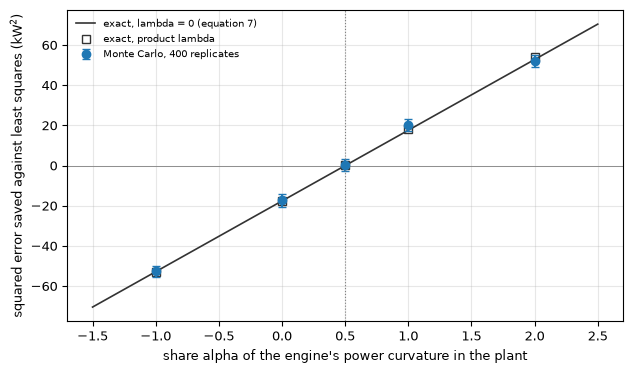

In [11]:
# Figure 2: the gain of the calibrated predictor over least squares against alpha: the exact curve at lambda
# 0, the exact values at the product's lambda and the Monte Carlo with its 95% interval
grid = np.linspace(-1.5, 2.5, 41)
curve = []
for alpha in grid:
    mu = basis.mean(alpha, 0.0, f_pool, z_ref, fit.d0["kW"])
    args = (Z_tr, mu[train_i], f_pool[train_i], Z_te, mu[test_i], f_pool[test_i], sigma_kw)
    risk_ls = theory.expected_sq_error_ls(Z_tr, mu[train_i], Z_te, mu[test_i], sigma_kw)
    curve.append((risk_ls - theory.expected_sq_error(*args, 0.0)).mean())
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(grid, curve, color="0.2", lw=1.2, label="exact, lambda = 0 (equation 7)")
alphas = list(monte_carlo)
ax.plot(alphas, [risk_table[a][3] for a in alphas], "s", mfc="none", color="0.2", label="exact, product lambda")
centre = [monte_carlo[a][0] for a in alphas]
spread = [monte_carlo[a][1] for a in alphas]
ax.errorbar(alphas, centre, yerr=spread, fmt="o", color="C0", capsize=3, label="Monte Carlo, 400 replicates")
ax.axhline(0, color="0.5", lw=0.6)
ax.axvline(0.5, color="0.5", lw=0.8, ls=":")
ax.set_xlabel("share alpha of the engine's power curvature in the plant")
ax.set_ylabel("squared error saved against least squares (kW$^2$)")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

The gain is a straight line in $\alpha$ with slope $2\lVert e_0\rVert^2$ that crosses zero at one half, and the simulation sits on it. To the left of the dotted line the engine's curvature is oversized or misaligned for the plant and the calibrated predictor loses to plain regression; to the right it wins. The figure does not show the size of the stake: at $\alpha = 1$, the plant fitted to the ten surveys, the gain is 17.605 kW$^2$ against a noise variance of 1506.4 kW$^2$, about one percent of it. Even a perfectly aligned engine can remove only that much of the squared error, because its curvature is small beside the noise.

### The curved capacity: an affine engine is only a shrinkage target

The throughput of the HP500 lane is the case $e \equiv 0$. Then (5) minus (6) reduces to

$$R_\lambda - R_{\mathrm{LS}} = \lambda^2 w_h^2 - 2\lambda\, r_h w_h - \sigma^2\,\tilde{\mathbf z}_h^{\top}\bigl(\mathbf G^{-1} - \mathbf A_\lambda\mathbf G\mathbf A_\lambda\bigr)\tilde{\mathbf z}_h, \qquad w_h = \tilde{\mathbf z}_h^{\top}\mathbf A_\lambda\boldsymbol\delta \tag{8}$$

The last term is a variance saving, always positive, that shrinks as the design grows; the first two come from the shrinkage's pull toward the engine's plane and vanish when the two planes coincide. An affine engine therefore contributes no curvature: CrusherBayes on the throughput is a ridge regression toward the engine's plane, nothing more. A capacity law that is curved in the setting changes that. The capacity study uses the published capacity of Rocha et al. (2024), a power law in the setting and the feed size, as the plant, and three engines: the shipped affine capacity, the plant's own form, and the same form with the exponents halved. The cell measures the alignment of each against the plant on two windows, the surveys' window and a wider one (setting 25 to 70 mm), with each engine's scale set by projecting the plant on its shape, as in the study's oracle (Tuo and Wu, 2015).

In [12]:
# For the three analytic capacity engines against the published capacity of Rocha et al. as the plant: the
# plant's and the engine's departure from a plane, rho and kappa, on two windows
print("window  engine  rms of r (t/h)  rms of e (t/h)  rho  kappa  gain 2<e,r>-|e|^2 as a share of |r|^2")
alignment = {}
for window in ("surveys", "wide"):
    pts = pools.window_points(window, 300)
    z = pools.design_matrix(pts, *pools.standardization(pts))
    plant = ROCHA["lam"] * rocha_shape(pts[:, 0], pts[:, 1], WI_BLEND)
    r = plant - z @ np.linalg.lstsq(z, plant, rcond=None)[0]
    for kind in engines.ANALYTIC:
        # The engine's scale is the least-squares projection of the plant on its shape, as in the study's oracle
        shape = engines.analytic_shape(kind, pts)
        f = (plant @ shape) / (shape @ shape) * shape
        e = f - z @ np.linalg.lstsq(z, f, rcond=None)[0]
        e_rms, r_rms = np.sqrt(np.mean(e**2)), np.sqrt(np.mean(r**2))
        rho = f"{np.mean(e * r) / (e_rms * r_rms):6.3f}" if e_rms > 1e-6 * r_rms else "  none"
        share = np.round(np.mean(e * (2 * r - e)) / r_rms**2, 3) + 0.0
        alignment[(window, kind)] = share
        print(f"{window:8s} {kind:11s} {r_rms:9.2f} {e_rms:14.2f} {rho:>8s} {e_rms / r_rms:7.3f} {share:12.3f}")
    bound = 100 * (r_rms / ident["sigma"]["tph"]) ** 2
    print(window, "plant curvature over noise, share of the variance: {:.1f} percent".format(bound))

window  engine  rms of r (t/h)  rms of e (t/h)  rho  kappa  gain 2<e,r>-|e|^2 as a share of |r|^2
surveys  affine          18.52           0.00     none   0.000        0.000
surveys  rocha           18.52          18.52    1.000   1.000        1.000
surveys  rocha_half      18.52           7.32    0.935   0.395        0.582
surveys plant curvature over noise, share of the variance: 1.6 percent
wide     affine          19.37           0.00     none   0.000        0.000
wide     rocha           19.37          19.37    1.000   1.000        1.000
wide     rocha_half      19.37          11.30    0.116   0.583       -0.205
wide plant curvature over noise, share of the variance: 1.8 percent


Against the published capacity the plant departs from a plane by 18.52 t/h on the surveys' window and 19.37 t/h on the wide one. The affine engine has no departure, so $\rho$ does not exist and the share of (7) is 0.000. The engine of the plant's own form has $\rho = 1.000$ and $\kappa = 1.000$, a share of 1.000: the best case of (7), where the engine's curvature is the plant's. The halved-exponent engine on the surveys' window has $\rho = 0.935$ and $\kappa = 0.395$, a share of 0.582, aligned and smaller than the plant's, so it gains. On the wide window its departure is 11.30 t/h but of another shape: $\rho = 0.116$, and $\kappa = 0.583$ exceeds $2\rho$, so (7) predicts a loss, and the share is -0.205.

The prediction of (7) is a claim about simulated predictors, so the next cell tests it against the committed capacity study: for each engine and window, the RMSE of the calibrated predictor with the true scale over the RMSE of least squares, at 160 training surveys, with the paired squared-error difference and its standard error, which is the evidence that resolves effects of one percent.

In [13]:
# From the committed capacity summaries at 160 surveys: the paired squared-error difference with its standard error,
# the ratio of RMSE, and the share of the RMSE that the plant's own form saves
print("paired squared-error difference, calibrated minus least squares, n = 160 ((t/h)^2; standard error after +-)")
for design in ("surveys", "wide", "extrapolation"):
    ratios = {}
    for kind in engines.ANALYTIC:
        cell = ccap[(kind, design, 160)]
        s, d = cell["predictors_summary"]["tph"], cell["paired"]["tph"]["cb_oracle"]["vs_ls"]
        ratios[kind] = s["cb_oracle"]["rmse"] / s["ls"]["rmse"]
        print(f"{design:14s} {kind:11s} {d['mean']:9.1f} +- {d['mcse']:.1f}   RMSE ratio {ratios[kind]:.4f}")
    saved = 100 * (1 - ratios["rocha"])
    print(design, "plant-form engine saves {:.1f} percent of the RMSE at n = 160".format(saved))
for kind in engines.ANALYTIC:
    s = ccap[(kind, "real", 10)]["predictors_summary"]["tph"]
    print("ten surveys, real design", kind, round(s["cb_oracle"]["rmse"] / s["ls"]["rmse"], 4))

paired squared-error difference, calibrated minus least squares, n = 160 ((t/h)^2; standard error after +-)
surveys        affine           -5.1 +- 0.5   RMSE ratio 0.9999
surveys        rocha          -360.4 +- 9.1   RMSE ratio 0.9917
surveys        rocha_half     -213.5 +- 3.6   RMSE ratio 0.9951
surveys plant-form engine saves 0.8 percent of the RMSE at n = 160
wide           affine           -4.4 +- 0.9   RMSE ratio 0.9999
wide           rocha          -429.1 +- 9.9   RMSE ratio 0.9902
wide           rocha_half       81.5 +- 5.7   RMSE ratio 1.0019
wide plant-form engine saves 1.0 percent of the RMSE at n = 160
extrapolation  affine          -73.0 +- 2.3   RMSE ratio 0.9985
extrapolation  rocha         -1057.0 +- 31.6   RMSE ratio 0.9777
extrapolation  rocha_half      232.2 +- 14.0   RMSE ratio 1.0049
extrapolation plant-form engine saves 2.2 percent of the RMSE at n = 160
ten surveys, real design affine 0.9757
ten surveys, real design rocha 0.966
ten surveys, real design rocha_hal

The figure draws the ratios of RMSE that the table summarizes, for each engine and window against the number of training surveys, with the five sizes on the axis.

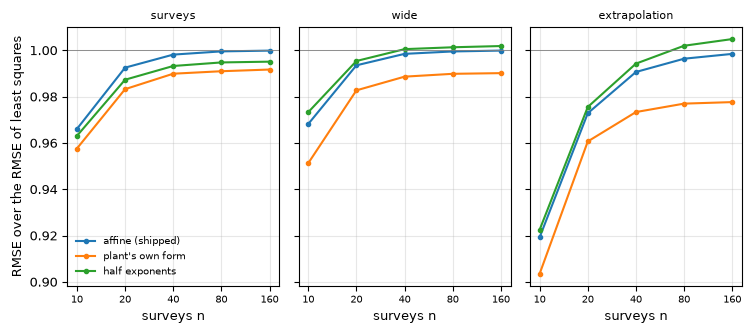

In [14]:
# Figure 3: from the committed capacity summaries, the RMSE of the calibrated predictor (true scale) over that
# of least squares against the number of surveys, per engine and window
names = {"affine": "affine (shipped)", "rocha": "plant's own form", "rocha_half": "half exponents"}
fig, axes = plt.subplots(1, 3, figsize=(7.6, 3.4), sharey=True)
for ax, design in zip(axes, ("surveys", "wide", "extrapolation")):
    for kind in engines.ANALYTIC:
        ratio = [ccap[(kind, design, n)]["predictors_summary"]["tph"] for n in NS]
        ax.plot(NS, [s["cb_oracle"]["rmse"] / s["ls"]["rmse"] for s in ratio], marker="o", ms=3, label=names[kind])
    ax.axhline(1, color="0.5", lw=0.6)
    ax.set_xscale("log")
    ax.set_xticks(NS)
    ax.set_xticklabels(NS, fontsize=7)
    ax.minorticks_off()
    ax.set_xlabel("surveys n")
    ax.set_title(design, fontsize=8)
axes[0].set_ylabel("RMSE over the RMSE of least squares")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

Each curve is below one where the engine helps. With the affine engine the ratio is 0.9757 on the ten surveys' own design and 0.9999 at 160 surveys on the surveys' window: the shrinkage gain of (8) decays with the number of surveys, as the next section makes exact. The engine of the plant's own form stays below one at 160 surveys, 0.9917 on the surveys' window, 0.9902 on the wide one and 0.9777 under extrapolation, a gain that persists and grows with the distance of the test points from the training window. The halved-exponent engine follows the alignment of the previous cell: 0.9951 where it is aligned, 1.0019 on the wide window and 1.0049 under extrapolation, where it is not. The printed paired squared-error differences at 160 surveys resolve what the ratios hide: the plant-form engine saves -360.4 plus or minus 9.1 (t/h)$^2$ on the surveys' window, -429.1 plus or minus 9.9 on the wide one and -1057.0 plus or minus 31.6 under extrapolation; the halved-exponent engine -213.5 plus or minus 3.6 where it is aligned and +81.5 plus or minus 5.7 and +232.2 plus or minus 14.0 where it is not; the affine engine -5.1 plus or minus 0.5, -4.4 plus or minus 0.9 and -73.0 plus or minus 2.3 (standard errors, negative meaning that the calibrated predictor is better). On the real design of the ten surveys the ratio is 0.9757 for the affine engine, which is shrinkage only, and 0.966 for the plant-form engine, about one point lower, which is its curvature. The figure also shows how little is at stake. The plant's curvature of 18.52 t/h on the surveys' window and 19.37 t/h on the wide one is small against a noise of 145.2 t/h, which caps the gain over the training window at 1.6 and 1.8 percent of the squared error (printed under the alignment table). The plant-form engine saves 0.8 and 1.0 percent of the RMSE inside the two windows and 2.2 percent under extrapolation at 160 surveys.

## Evidence

### The risk-optimal discrepancy scale

Average (5) over the training surveys themselves as held-out points, with new noise: the fixed-design risk. It separates the gain into two parts,

$$\bar R_\lambda - \bar R_{\mathrm{LS}} = -C + \frac1n\sum_{k=1}^{3}\frac{\lambda^2 g_k\tilde\delta_k^2 - \sigma^2(2\lambda g_k + \lambda^2)}{(g_k + \lambda)^2}, \qquad C = \frac1n\sum_{i=1}^{n} e_i(2 r_i - e_i) \tag{9}$$

with $g_k$ the eigenvalues of $\mathbf G$ and $\tilde\delta_k$ the components of the plane mismatch $\boldsymbol\delta$ in its eigenvectors. The curvature gain $C$ is the empirical form of (7) and does not decay with $n$. The plane gain, the sum, is a variance saving bounded by $3\sigma^2/n$, and it decays. Each term of the sum is smallest at $\lambda_k^{\star} = \sigma^2/\tilde\delta_k^2$, and since the prior of Kennedy and O'Hagan gives $\lambda = \sigma^2/\tau^2$, that is

$$\tau^2 = \tilde\delta_k^2 \tag{10}$$

The risk-optimal discrepancy scale in a direction is the size of the mismatch between the engine's plane and the plant's plane in that direction. A single $\tau$ cannot match three mismatches, and (9) gives the loss of every compromise. This reads a Bayesian prior as a frequentist device: the prior is right, for prediction, when its scale is the size of the error it is meant to absorb. The cell evaluates (5) at the training points on a grid of $\tau$ for the plant fitted to the ten surveys, on the ten surveys' own design and on designs of 40 and 160 points from the pool, and takes the three $|\tilde\delta_k|$ of (10) at each.

In [15]:
# The plant fitted to the ten surveys is the engine at the fitted scalars plus the fitted discrepancy; the ten
# surveys' design and two designs of 40 and 160 points from the pool
points10 = pools.survey_points()
engine10 = engines.product_eval(points10, fit.theta0, workers=1, jac=False)
mu10 = engine10["kW"] + pools.design_matrix(points10, mu_ref, sd_ref) @ fit.d0["kW"]
mu_pool = f_pool + z_ref @ fit.d0["kW"]
rng_tau = np.random.default_rng(20261121)
designs = {10: (points10, mu10, engine10["kW"])}
for n in (40, 160):
    pick = rng_tau.choice(300, n, replace=False)
    designs[n] = (pool[pick], mu_pool[pick], f_pool[pick])
taus = np.logspace(np.log10(4), np.log10(400), 41)
tau_rmse, tau_delta, tau_ls = {}, {}, {}
print("n  best tau  RMSE at best  RMSE at tau = 36  RMSE of LS  saved at 36  |delta_k| of equation (10)  "
      "tau within 1 kW")
for n, (pts, mu, f) in designs.items():
    Z_n = pools.design_matrix(pts, *pools.standardization(pts))
    risk = [theory.expected_sq_error(Z_n, mu, f, Z_n, mu, f, sigma_kw, sigma_kw**2 / t**2).mean() for t in taus]
    tau_rmse[n] = np.sqrt(risk)
    tau_ls[n] = math.sqrt(theory.expected_sq_error_ls(Z_n, mu, Z_n, mu, sigma_kw).mean())
    tau_delta[n] = np.abs(theory.fixed_design_terms(Z_n, mu, f, sigma_kw, lam_prod, n)["delta_k"])
    at_36 = np.interp(math.log(36.0), np.log(taus), tau_rmse[n])
    near = taus[tau_rmse[n] <= tau_rmse[n].min() + 1.0]
    best = taus[np.argmin(tau_rmse[n])]
    mismatch = " ".join(f"{v:.1f}" for v in np.sort(tau_delta[n]))
    print(f"{n:3d} {best:9.2f} {tau_rmse[n].min():13.3f} {at_36:17.3f} {tau_ls[n]:11.3f} {tau_ls[n] - at_36:13.3f}"
          f"   {mismatch}   {near.min():.1f} to {near.max():.1f}")
    print("    cost of tau = 36 over the best: {:.3f}".format(at_36 - tau_rmse[n].min()))

n  best tau  RMSE at best  RMSE at tau = 36  RMSE of LS  saved at 36  |delta_k| of equation (10)  tau within 1 kW
 10     35.65        43.642            43.644      44.675         1.031   12.6 36.7 44.0   22.5 to 400.0
    cost of tau = 36 over the best: 0.002
 40     31.77        40.193            40.195      40.410         0.215   8.0 36.8 42.7   14.2 to 400.0
    cost of tau = 36 over the best: 0.001
160     31.77        39.170            39.171      39.394         0.223   13.2 31.4 38.8   7.1 to 400.0
    cost of tau = 36 over the best: 0.000


At the ten surveys' design the three mismatches $|\tilde\delta_k|$ are 12.6, 36.7 and 44.0 kW and the fixed-design risk is smallest at $\tau = 35.65$ kW, between them. At the product's 36 kW the RMSE is 43.644 kW against 43.642 at the optimum and 44.675 for least squares, a saving of 1.031 kW. At 40 and 160 points the best $\tau$ is 31.77 kW for both and the saving at 36 kW is 0.215 and 0.223 kW: it persists with the number of points because the curvature gain $C$ of (9) does not decay, while the plane gain has. The RMSE at the product's scale is within 0.002 kW of the best at all three sizes, as the line under each row shows.

The figure draws the fixed-design RMSE against $\tau$ for the three designs, with least squares at the same sizes as dashed horizontal lines, the three mismatches of the ten surveys' design as dotted verticals and the product's 36 kW as a solid vertical.

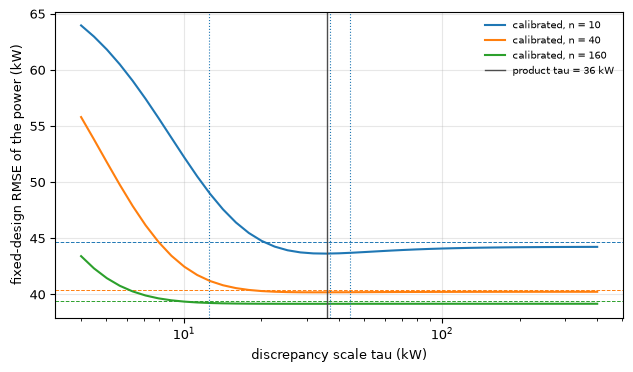

In [16]:
# Figure 4: the fixed-design RMSE of the calibrated predictor against the discrepancy scale tau, with the per-
# direction optima |delta_k| of the ten surveys marked
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for n, color in zip(tau_rmse, ("C0", "C1", "C2")):
    ax.plot(taus, tau_rmse[n], color=color, label=f"calibrated, n = {n}")
    ax.axhline(tau_ls[n], color=color, lw=0.7, ls="--")
for d in tau_delta[10]:
    ax.axvline(d, color="C0", lw=0.8, ls=":")
ax.axvline(cb.DISCREPANCY_SD["kW"], color="0.3", lw=1.0, label="product tau = 36 kW")
ax.set_xscale("log")
ax.set_xlabel("discrepancy scale tau (kW)")
ax.set_ylabel("fixed-design RMSE of the power (kW)")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

The product's scale sits at the bottom of a flat valley. Below the smallest mismatch, 12.6 kW, the cost is steep, since the prior then forbids the plane the data need. Toward large $\tau$ the predictor tends to least squares plus the engine's departure $e_h$ (the ridge form (3) at $\lambda = 0$), so each curve stays below its dashed least-squares line by the curvature gain instead of meeting it. These are the fixed-design optima of (10), computed at the training points; at held-out points the cross term of (8) enters and the optimum moves, which the next cell reads from the committed study. The orthogonal discrepancy of Plumlee (2017) and the scaled prior of Gu and Wang (2018) change this picture only through the penalty. The scaled prior shrinks most in the directions the design measures best, those with large $g_k$, which is the opposite of what (10) asks when those directions carry the large mismatches, and in the diffuse limit the orthogonal prior leaves the predictions unchanged and changes only what the scalars mean.

The fixed-design optimum above answers where (10) places the scale at the training points. The committed study also computes the risk at held-out points, over 400 random designs per size, on the plant fitted to the ten surveys. For ten and 160 surveys it records the best $\tau$, the RMSE of the calibrated predictor at the best and at the product's 36 kW, and the RMSE of least squares and of the line in the setting. The cell reads those and prints the differences that decide the order of the methods.

In [17]:
# The held-out risk against tau over 400 random designs, read from the committed study: the best scale and the gaps
# that order the calibrated predictor, least squares and the line in the setting
held_out = tau_cov["tau"]["by_n"]
print("n  best tau  RMSE best  RMSE at 36  RMSE LS  RMSE line  36 minus best  36 minus line  best minus line  "
      "mismatches")
for n in ("10", "160"):
    row = held_out[n]
    at_36, best, line = row["rmse_cb_at_product_tau"], row["rmse_cb_best"], row["rmse_line"]
    values = (best, at_36, row["rmse_ls"], line, at_36 - best, at_36 - line, best - line)
    mismatch = " ".join(f"{v:.1f}" for v in sorted(row["abs_delta_k"]))
    print(f"{n:>3s} {row['tau_best']:9.1f} " + " ".join(f"{v:10.3f}" for v in values) + "   " + mismatch)

n  best tau  RMSE best  RMSE at 36  RMSE LS  RMSE line  36 minus best  36 minus line  best minus line  mismatches
 10      25.2     44.873     45.144     46.767     45.068      0.271      0.076     -0.195   10.0 29.5 37.2
160      28.3     39.174     39.175     39.441     40.607      0.001     -1.432     -1.433   10.0 29.5 37.2


At held-out points over random designs the best scale is 25.2 kW at ten surveys and 28.3 kW at 160, with mismatches of 10.0, 29.5 and 37.2 kW against the 12.6, 36.7 and 44.0 kW of the ten surveys' own design: two optima for two questions, the fixed-design one at the training points, 35.65 kW, and the held-out one, 25.2 kW, in the same flat valley. At ten surveys the product's 36 kW costs 0.271 kW of RMSE against the best, and that is the whole span in which the order against the line is decided: at 36 kW the calibrated predictor is 0.076 kW behind the line and at the best scale 0.195 kW ahead of it (the last two difference columns, with the sign of the second against the line). A difference of 0.2 kW is far below what ten surveys with a noise of 38.812 kW can show, so on ten surveys the scale does not separate the method from the line, and the noise does. Against least squares the method wins at every scale of the valley. At 160 surveys the calibrated predictor is 1.432 kW ahead of the line at 36 kW and at the best scale alike.

### The information ceiling of the capacity base

A different question: not how well the predictor predicts, but what the surveys can teach about the scalars. For the capacity base $Q_{\mathrm{ref}}$ the sensitivity of the throughput to $\ln Q_{\mathrm{ref}}$ is the throughput itself, affine in the setting and therefore in the span of the discrepancy regressors: $\mathbf j = \mathbf Z\mathbf c$. Any change of $\ln Q_{\mathrm{ref}}$ can then be absorbed by the throughput discrepancy. The Fisher information of the marginal likelihood, with the discrepancy integrated out, is

$$\mathcal I(\ln Q_{\mathrm{ref}}) = \mathbf c^{\top}\mathbf G\bigl(\sigma^2\mathbf I + \tau^2\mathbf G\bigr)^{-1}\mathbf c \;\le\; \frac{\lVert\mathbf c\rVert^2}{\tau^2} \tag{11}$$

for every design and every number of surveys, because each eigenvalue $g/(\sigma^2 + \tau^2 g)$ is below $1/\tau^2$: surveys at the same setting range cannot push the information past the ceiling. The power informs only the product of the capacity base, the work index and the power slope, a structural confounding of the engine, so the posterior standard deviation of $\ln Q_{\mathrm{ref}}$ over its prior one has a floor in the linearized Gaussian model at fixed speed,

$$\frac{\mathrm{sd}(\ln Q_{\mathrm{ref}}\mid\mathcal D)}{s_Q} \;\ge\; \Bigl(1 + s_Q^2\,\frac{\lVert\mathbf c\rVert^2}{\tau^2} + \frac{s_Q^2}{s_W^2 + s_\zeta^2}\Bigr)^{-1/2} \tag{12}$$

with $s_Q$, $s_W$ and $s_\zeta$ the prior standard deviations of the logarithms of the capacity base, the work index and the power slope. The cell recomputes (11) and (12), and the throughput-only ratio $(1 + s_Q^2\mathcal I)^{-1/2}$, from the ten surveys with the engine at the fitted scalars, taking the sensitivity by central differences of the engine in $\ln Q_{\mathrm{ref}}$, and sets them beside the committed values of the study.

In [18]:
# The information of the ten surveys about ln Q_ref from throughput, with the discrepancy integrated out: the
# sensitivity is the engine's throughput itself and lies in the span of the regressors
step = 1e-4
up, down = fit.theta0.copy(), fit.theta0.copy()
up[0] += step
down[0] -= step
ups = [evaluate(op, cb.scalars_of(np.concatenate([up, [0.0, 0.0]]))).throughput_tph for op in problem.ops]
downs = [evaluate(op, cb.scalars_of(np.concatenate([down, [0.0, 0.0]]))).throughput_tph for op in problem.ops]
sens = (np.array(ups) - np.array(downs)) / (2 * step)
coef = np.linalg.lstsq(Z10, sens, rcond=None)[0]
out_of_span = np.linalg.norm(sens - Z10 @ coef) / np.linalg.norm(sens)
sig_t, tau_t = fit.sigma["tph"], cb.DISCREPANCY_SD["tph"]
G10 = Z10.T @ Z10
# Equation (11): the information and the ceiling it can never pass
info = coef @ G10 @ np.linalg.solve(sig_t**2 * np.eye(3) + tau_t**2 * G10, coef)
ceiling = coef @ coef / tau_t**2
prior_sd = {p.name: p.sd for p in cb.PRIORS}
s_q, s_w, s_z = prior_sd["q_ref_tph"], prior_sd["wi_kwh_t"], prior_sd["zeta"]
# Equation (12): the floor of the contraction of ln Q_ref for surveys at this speed over the same setting range,
# and the throughput-only ratio
floor = (1 + s_q**2 * ceiling + s_q**2 / (s_w**2 + s_z**2)) ** -0.5
tph_only = (1 + s_q**2 * info) ** -0.5
shown = ident["ten_surveys"]
print("quantity  computed here  committed summary")
print(f"information from throughput  {info:9.3f}  {shown['tph_lnq_info_exact']:9.3f}")
print(f"ceiling |c|^2 / tau^2  {ceiling:9.3f}  {shown['tph_lnq_ceiling']:9.3f}")
print(f"throughput-only sd ratio  {tph_only:9.4f}  {shown['tph_only_ratio_lnq']:9.4f}")
print(f"floor, fixed speed, same settings  {floor:9.4f}  {shown['floor_ratio_lnq_any_n_fixed_speed']:9.4f}")
print("sensitivity outside the span of the regressors, relative: below 1e-9 is {}".format(out_of_span < 1e-9))
print("linearized model with both outputs {:.4f} | sampler on the ten surveys {:.4f}".format(
    shown["linearized_ratio"]["q_ref_tph"], shown["measured_ratio_sampled_scale"]["q_ref_tph"]))

quantity  computed here  committed summary
information from throughput     54.878     54.878
ceiling |c|^2 / tau^2     60.792     60.792
throughput-only sd ratio     0.4751     0.4751
floor, fixed speed, same settings     0.4240     0.4240
sensitivity outside the span of the regressors, relative: below 1e-9 is True
linearized model with both outputs 0.4570 | sampler on the ten surveys 0.4688


The recomputed quantities match the committed ones: the information from the throughput is 54.878 against a ceiling of 60.792, the throughput-only ratio of standard deviations is 0.4751 and the floor for any number of surveys at the fixed speed over the same setting range is 0.4240. The sensitivity lies outside the span of the regressors by less than 1e-9 in relative terms, which is the condition of (11). With both outputs in the linearized model the ratio is 0.4570, and the sampler run on the ten surveys measured 0.4688. The ten surveys already hold 54.878 of the at most 60.792 that the throughput can ever give about the capacity base.

The figure has two panels from the committed identifiability summary. On the left, the posterior over prior standard deviation of $\ln Q_{\mathrm{ref}}$ against the number of surveys drawn from the surveys' window, with the speed fixed and varied, the floor of (12) and the sampler's value at ten surveys. On the right, the eight scalars at ten surveys, the linearized model against the sampler.

speeds of the varied design (rpm): [324.0, 360.0, 396.0]
fixed_speed   n = 10: 0.4617   n = 640: 0.4399
varied_speed  n = 10: 0.4629   n = 640: 0.4405


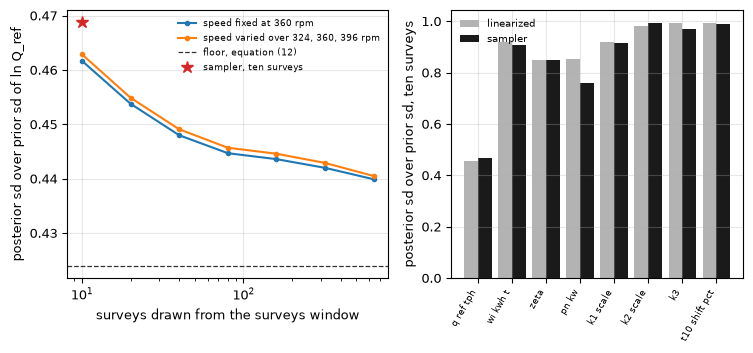

In [19]:
# Figure 5: the contraction of ln Q_ref against the number of surveys, fixed speed and varied speed, with the
# floor and the sampler's value; and the eight scalars at ten surveys, linearized against sampled
fig, (left, right) = plt.subplots(1, 2, figsize=(7.6, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
sweep_n = ident["sweep"]["n"]
speeds = {"fixed_speed": "speed fixed at 360 rpm",
          "varied_speed": "speed varied over 324, 360, 396 rpm"}
for key, label in speeds.items():
    left.plot(sweep_n, [ident["sweep"][key][str(n)]["q_ref_tph"] for n in sweep_n], marker="o", ms=3, label=label)
left.axhline(floor, color="0.2", ls="--", lw=0.9, label="floor, equation (12)")
measured = shown["measured_ratio_sampled_scale"]
left.plot([10], [measured["q_ref_tph"]], "*", color="C3", ms=9, label="sampler, ten surveys")
left.set_xscale("log")
left.set_xlabel("surveys drawn from the surveys window")
left.set_ylabel("posterior sd over prior sd of ln Q_ref")
left.legend(frameon=False, fontsize=6.5)
print("speeds of the varied design (rpm): {}".format(ident["sweep"]["speeds_rpm"]))
for key in ("fixed_speed", "varied_speed"):
    first, last = (ident["sweep"][key][str(n)]["q_ref_tph"] for n in (sweep_n[0], sweep_n[-1]))
    print(f"{key:13s} n = {sweep_n[0]}: {first:.4f}   n = {sweep_n[-1]}: {last:.4f}")
names = list(shown["linearized_ratio"])
pos = np.arange(len(names))
right.bar(pos - 0.2, [shown["linearized_ratio"][k] for k in names], width=0.4, color="0.7", label="linearized")
right.bar(pos + 0.2, [measured[k] for k in names], width=0.4, color="0.1", label="sampler")
right.set_xticks(pos)
right.set_xticklabels([k.replace("_", " ") for k in names], rotation=60, ha="right", fontsize=6.5)
right.set_ylabel("posterior sd over prior sd, ten surveys")
right.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

The left panel is the saturation. From 10 to 640 surveys the ratio falls only from 0.4617 to 0.4399 at the fixed speed, and from 0.4629 to 0.4405 with the speed varied over 324, 360 and 396 rpm, which stays above the floor of 0.4240 and, at ten surveys, below the sampler's 0.4688. Varying the speed does not break the ceiling because the engine's capacity is nearly flat around its optimum speed, so the sensitivity moved out of the regressors' span is a small fraction of the throughput. More surveys at the same speed and over the same setting range are therefore not a way to learn the capacity base, and the right panel shows the same: only the capacity base is contracted to about half, while the other scalars stay between 0.7608 and 0.9915 of their prior width. The panel does not show which design would help, which needs another measured output; it shows that this one cannot.

### Where the method breaks: curvature it cannot follow, extrapolation and the linearization

The closed form is exact, and exactness is not the same as usefulness. Four limits show in the committed summaries and in the previous cells. First, an oversized or misaligned engine curvature: outside $0 < \kappa < 2\rho$ the gain of (7) is negative, as the rows $\alpha = -1$ and the halved-exponent engine on the wide window showed. Second, an affine engine: (8) leaves only a shrinkage that decays with $n$. Third, extrapolation against curvature the engine does not model. The plant V1(1, 2) adds a curvature $q$ in the setting that is orthogonal to the engine's own, $\langle e, q\rangle = 0$, so by (7) it enters $r$ but not the gain, and on the training window the gain should stay where it was; outside the window, where $q$ grows quadratically, no regression of either kind can know it. Fourth, the linearization: (11) and (12) are properties of the model linearized in the scalars, and the sampler measures what the linearization leaves out. The cell prints the committed numbers for each, and asks the engine's own envelope gate how much of each window lies outside the support the product calibrated.

In [20]:
# Where the closed form stops describing the method, from the committed summaries: curvature the engine cannot
# follow, a curvature of the wrong shape, and the linearization of the scalars
for kind in ("rocha", "rocha_half"):
    for design in ("surveys", "wide", "extrapolation"):
        s = ccap[(kind, design, 160)]["predictors_summary"]["tph"]
        ratio = s["cb_oracle"]["rmse"] / s["ls"]["rmse"]
        print(f"{kind:11s} {design:14s} n = 160  RMSE ratio, calibrated over LS  {ratio:.4f}")
print("curvature the engine cannot follow, V1(1, 2): paired gain over LS (kW^2) and 80% coverage")
gains = {}
for name in ("a1", "a1_k2"):
    for design in ("surveys", "extrapolation"):
        cell = v1_cells[(name, design)]
        gain = cell["paired"]["kW"]["cb_oracle"]["vs_ls"]
        cover = cell["predictors_summary"]["kW"]["cb_oracle"]["coverage80"]
        label = "V1(1, 2)" if name == "a1_k2" else "V1(1)"
        gains[(name, design)] = -gain["mean"]
        print(f"{label:9s} {design:14s} gain  {-gain['mean']:8.2f} +- {gain['mcse']:.2f}  coverage  {cover:.3f}")
print("surveys window, gain with the added curvature minus without it: {:.2f}".format(
    gains[("a1_k2", "surveys")] - gains[("a1", "surveys")]))
# The share of each window the engine's own envelope gate flags as outside its calibrated support
for window in ("surveys", "wide"):
    pts = pools.window_points(window, 300)
    codes = [k for c, f, _ in pts for k in check_envelope(operating_from_survey(c, f), f).codes]
    counts = {k: codes.count(k) for k in sorted(set(codes))}
    print("window", window, "gate codes over 300 points", counts)
print("linearized against sampled contraction at ten surveys (ratio of posterior to prior sd)")
for k in shown["linearized_ratio"]:
    lin, smp = shown["linearized_ratio"][k], shown["measured_ratio_sampled_scale"][k]
    print(f"{k:14s} linearized  {lin:.4f}  sampled  {smp:.4f}  gap  {smp - lin:+.4f}")

rocha       surveys        n = 160  RMSE ratio, calibrated over LS  0.9917
rocha       wide           n = 160  RMSE ratio, calibrated over LS  0.9902
rocha       extrapolation  n = 160  RMSE ratio, calibrated over LS  0.9777
rocha_half  surveys        n = 160  RMSE ratio, calibrated over LS  0.9951
rocha_half  wide           n = 160  RMSE ratio, calibrated over LS  1.0019
rocha_half  extrapolation  n = 160  RMSE ratio, calibrated over LS  1.0049
curvature the engine cannot follow, V1(1, 2): paired gain over LS (kW^2) and 80% coverage
V1(1)     surveys        gain     20.38 +- 0.60  coverage  0.799
V1(1)     extrapolation  gain     55.79 +- 1.68  coverage  0.801
V1(1, 2)  surveys        gain     22.08 +- 0.62  coverage  0.788
V1(1, 2)  extrapolation  gain   -916.50 +- 3.26  coverage  0.269
surveys window, gain with the added curvature minus without it: 1.70
window surveys gate codes over 300 points {'f80_lt_css': 5}
window wide gate codes over 300 points {'css_outside_calibrated': 182, 

The first two limits are in the capacity rows: the halved-exponent engine is at 1.0019 on the wide window and 1.0049 under extrapolation, a loss, and the affine engine is at 0.9999 at 160 surveys. For the third, on the surveys' window the added curvature leaves the gain at 22.08 kW$^2$ against 20.38 without it, a difference of 1.70 kW$^2$ against Monte Carlo standard errors of 0.60 and 0.62 on the two gains, so about two standard errors of the difference away from unchanged, as (7) says up to simulation noise. Under extrapolation the gain falls from 55.79 to -916.50 kW$^2$ and the 80 percent band covers 0.269 of the test points instead of 0.801: no predictor in the study can be trusted outside its training window against a curvature it does not model. For the fourth, the linearized and the sampled contraction agree to 0.0005 for zeta, 0.0002 for the $K_1$ scale and 0.0126 for the work index, but the no-load power is 0.8525 linearized against 0.7608 sampled, a gap of -0.0917, and $K_3$ is 0.9941 against 0.9704: the sampler contracts these two scalars more than the linearized model does. The engine is affine in the no-load power, whose sensitivity is 1 at every operating point, so nonlinearity in that scalar cannot be the cause. The study names the truncated priors that the linearized model drops, the noise scale that the sampler learns and the linearization at the prior centre as the candidates, and this notebook does not decide between them, so the sampler remains the reference. The engine's own envelope gate agrees with the extrapolation regime: among 300 points of the surveys' window it flags 5 whose feed is finer than the setting (`f80_lt_css`) and none outside the calibrated support, while on the wide window it flags 182 for the setting and 7 for the feed size, so the cases where the predictor fails are the ones the product already marks as outside its calibration.

### Using it on your own data

The diagnostics need a table of surveys with the setting, the feed size and the measured outputs, as in the `hp500-survey` contract, and the engine's values at the scalars you will use. The steps, applied below to the ten surveys' power as if they were your table:

1. Compute $\mathbf e$ and $\hat{\mathbf r}$ by (4). If $\mathbf e$ is below about 1e-9 of the engine's level, as the throughput was, the engine is affine in your regressors, and the method is a ridge toward its plane with no persistent gain.
2. Estimate the curvature gain by $\hat C = \frac1n\sum_i e_i(2\hat r_i - e_i)$. Because $\mathbf e$ is orthogonal to the regressors, $\mathbf e^{\top}\hat{\mathbf r} = \mathbf e^{\top}(\mathbf r + \boldsymbol\varepsilon)$ and the estimator is unbiased, with standard error $2\hat\sigma\lVert\mathbf e\rVert/n$ and $\hat\sigma^2 = \lVert\hat{\mathbf r}\rVert^2/(n - 3)$, which includes the plant's own curvature and so is an upper estimate. A $z$ score near zero means the table cannot tell.
3. Put a Fisher-$z$ interval on the correlation $\hat\rho$ of $\mathbf e$ and $\hat{\mathbf r}$, with $\sqrt{n - 3}$ in the denominator.
4. Choose $\tau$ from (10). A fitted plane is noisy, with $\mathbb E\,\hat\delta_k^2 = \delta_k^2 + \sigma^2/g_k$, so the estimate per direction is $\hat\tau_k = \sqrt{\max(\hat\delta_k^2 - \hat\sigma^2/g_k, 0)}$.

The cell does all four, at the fitted scalars and at the shipped ones.

In [21]:
# The diagnostic on a table of your own, here the ten surveys: the engine's departure e and the measured
# residual r-hat of the power, the curvature gain it implies with its standard error, and the scale the data
# allow for tau
print("scalars  e rms  C-hat  se(C-hat)  z  rho-hat  95% interval of rho  sigma-hat  tau-hat per direction")
for label, pair in engine_at.items():
    f = pair[1]
    e, r_hat = plane[(label, "kW")]
    sigma_hat = math.sqrt(np.sum(r_hat**2) / 7)
    # C-hat = mean of e(2 r-hat - e) is unbiased for C because e is orthogonal to the regressors; its standard
    # error is 2 sigma |e| / n
    c_hat = np.mean(e * (2 * r_hat - e))
    se = 2 * sigma_hat * np.linalg.norm(e) / 10
    rho_hat = np.corrcoef(e, r_hat)[0, 1]
    z_fisher = math.atanh(rho_hat)
    lo, hi = math.tanh(z_fisher - 1.96 / math.sqrt(7)), math.tanh(z_fisher + 1.96 / math.sqrt(7))
    # The plane mismatch in the eigendirections of G, less the variance of the fitted plane (sigma^2 / g_k)
    g, V = np.linalg.eigh(Z10.T @ Z10)
    delta = V.T @ (np.linalg.lstsq(Z10, f, rcond=None)[0] - np.linalg.lstsq(Z10, y["kW"], rcond=None)[0])
    tau_hat = np.sqrt(np.maximum(delta**2 - sigma_hat**2 / g, 0.0))
    e_rms = np.sqrt(np.mean(e**2))
    print(f"{label:8s} {e_rms:7.2f} {c_hat:7.1f} {se:9.1f} {c_hat / se:5.2f} {rho_hat:8.3f} [{lo:6.2f}, {hi:5.2f}] "
          f"{sigma_hat:10.2f} {tau_hat.round(1)}")

scalars  e rms  C-hat  se(C-hat)  z  rho-hat  95% interval of rho  sigma-hat  tau-hat per direction
fitted      6.13   150.8     153.8  0.98    0.463 [ -0.24,  0.85]      39.66 [49.8 13.5 36.6]
shipped     5.63   136.4     141.3  0.97    0.450 [ -0.25,  0.84]      39.66 [ 46.8 112.4  40.3]


At the fitted scalars the estimate of the curvature gain is 150.8 kW$^2$ with a standard error of 153.8, a $z$ of 0.98, and the correlation 0.463 has a 95 percent interval of -0.24 to 0.85; at the shipped scalars the estimate is 136.4 with 141.3 (a $z$ of 0.97). The measured residual can therefore say that the engine's curvature is plausibly aligned with the plant's, and cannot exclude a zero or negative gain, because the noise, $\hat\sigma$ = 39.66 kW, is large against the engine's departure of 6.13 kW; this is why the held-out comparison of notebook 03 could not separate CrusherBayes from the line. It can say that the throughput engine is affine. For $\tau$, the per-direction estimates at the fitted scalars are 49.8, 13.5 and 36.6 kW, around the product's 36 kW; at the shipped scalars they are 46.8, 112.4 and 40.3, because the shipped engine's plane is far from the data's plane in one direction, a mismatch that the scalars absorb once they are learned. Where the estimates disagree, err high: the valley of the risk curve is flat above the smallest mismatch and steep below it.

## Results

**Answer:** Only through the part of its output that is not a plane. CrusherBayes with its scalars given beats least squares on the same regressors if and only if the engine's departure from a plane has the plant's sign and is no more than twice its size, $0 < \kappa < 2\rho$, and on the plants of the study the gain is $(2\alpha - 1)$ times 17.605 kW$^2$, crossing zero at $\alpha = 0.5$; a Monte Carlo of 400 replicates confirms it, 0.292 kW$^2$ with a half-width of 2.839 against the exact 0.479 at the crossing. The throughput of the HP500 lane is affine in the setting at every value of the scalars, so its departure from a plane is below 1e-9 of its level and the method can only shrink toward the engine's plane there (a ratio of 0.9999 to least squares at 160 surveys), whereas an engine of the plant's own form gains 0.9917 on the surveys' window and 0.9777 under extrapolation. On the power the engine departs from a plane by 6.132 kW against a measured residual of 33.182 kW and a noise of 38.812 kW, so on the ten surveys the data cannot decide the sign of the gain, with an estimate of 150.8 kW$^2$ and a standard error of 153.8. The discrepancy scale does not separate the method from the line on ten surveys: the fixed-design optimum on the ten surveys' design is 35.65 kW and the held-out optimum of the committed study is 25.2 kW, the product's 36 kW lies in the flat valley of both, and the scale decides the order against the line by 0.271 kW, far below what ten surveys with a noise of 38.812 kW can show. What more surveys at this speed over the same setting range can never change is the capacity base, whose information is capped at 60.792 and whose contraction cannot fall below 0.4240, against 0.4688 measured.

## Summary

The notebook took CrusherBayes with its scalars fixed, the case in which its predictive is a ridge regression toward the engine's plane plus the engine's departure from that plane, and measured when that departure pays. The exact risk, confirmed by a simulation on a virtual plant, says that the engine's curvature gains over a regression on the same regressors only when it is aligned with the plant's and no more than twice as large, gains $(2\alpha - 1)$ times 17.605 kW$^2$ across the family of plants and does not shrink with the number of surveys. The HP500 throughput is affine in the setting, so for it the method is only a shrinkage that decays, and an engine of the right curved form is what would make it pay. The discrepancy scale of the product sits in a flat valley, 36 kW against a fixed-design optimum of 35.65 kW and a held-out optimum of 25.2 kW, and it decides the order against the line by 0.271 kW at ten surveys. The ten surveys cannot say which side of one half the plant lies on, because the engine's 6.132 kW of curvature is small beside a noise of 38.812 kW, and they leave the capacity base at 0.4688 of its prior width where no number of surveys at this speed over the same setting range can pass 0.4240.

The method breaks where the curvature does not match, where it is asked to extrapolate against a curvature it does not model, with a coverage of 0.269 in the study, and where the linearized contraction of a scalar differs from the sampled one, by 0.0917 for the no-load power, a gap the notebook does not attribute. On a table of your own the useful outputs are the engine's departure, the standard error of the curvature gain and a per-direction estimate of the discrepancy scale.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- Plumlee, M. (2017), Bayesian calibration of inexact computer models, Journal of the American Statistical Association 112(519), 1274-1285. https://doi.org/10.1080/01621459.2016.1211016
- Tuo, R., Wu, C. F. J. (2015), Efficient calibration for imperfect computer models, The Annals of Statistics 43(6), 2331-2352. https://doi.org/10.1214/15-AOS1314
- Gu, M., Wang, L. (2018), Scaled Gaussian stochastic process for computer model calibration and prediction, SIAM/ASA Journal on Uncertainty Quantification 6(4), 1555-1583. https://doi.org/10.1137/17M1159890